# What makes a book loved by readers?

**Page Turners** is a Python data analysis project exploring Goodreads book ratings, popularity and publication trends using the Goodbooks-10k dataset.

The aim of this project is to explore patterns in readers' ratings and understand how book popularity, rating distributions, user rating activity and publication years relate to readers' evaluations.

## Research questions
The project focuses on four main research questions:
1. **Popularity & ratings:** is there a relationship between the number of ratings a book receives and its average rating?
2. **Rating distributions:** how are ratings distributed across the five rating levels and how do these distributions differ between books?
3. **Reader behavior:** do more active readers rate books differently?
4. **Publication year:** is there a relationship between a book's publication year and its average rating?

## Notebook overview
This notebook shows how to use the `pageturners` package to reproduce and explore the project's analysis:

- **Setup**: import the package and prepare the environment.
- **Load the original datasets**.
- **Explore the data** and perform preliminary data quality checks.
- **Popularity & ratings**: investigate the relationship between book popularity and average rating.
- **Rating distributions**: explore overall and individual book rating distributions.
- **Reader behavior**: analyze user rating activity.
- **Publication year**: explore rating trends by year and decade.
- **Conclusions**.
- **Interactive Streamlit application**.

The notebook reuses the functions defined in the `pageturners/` package for data loading, statistical analysis and visualization.

**How to run it.** Follow the environment setup instructions in the README, install the requirements (`python -m pip install -r requirements.txt`), open `notebooks/pageturners.ipynb` in VS Code and select the appropriate Python kernel. Then run all cells from top to bottom.

## Setup
The notebook is located in the `notebooks/` folder, while the `pageturners` package and the `data/` folder are in the main project directory.

To allow Python to find and import the `pageturners` package, the main project directory is first identified and added to the list of paths where Python searches for modules (`sys.path`).

In [ ]:
import os
import sys

import matplotlib.pyplot as plt

# Locate the main project directory.
PROJECT_ROOT = os.getcwd()

if os.path.basename(PROJECT_ROOT) == "notebooks":
    PROJECT_ROOT = os.path.dirname(PROJECT_ROOT)

# Allow Python to import the pageturners package.
if PROJECT_ROOT not in sys.path:
    sys.path.append(PROJECT_ROOT)

# Set the working directory to the project root.
os.chdir(PROJECT_ROOT)

print("Project folder:", os.path.basename(PROJECT_ROOT))

Project folder: pageturners


Once Python can access the project directory, the modules required for data loading, statistical analysis and visualization can be imported.

In [ ]:
from pageturners import analysis, data, plots

## Load the datasets
The project uses the [Goodbooks-10k dataset](https://github.com/zygmuntz/goodbooks-10k).

The main analysis is based on two CSV files:
- `books.csv`: book metadata, including titles, authors, publication years and ratings.
- `ratings.csv`: individual user ratings used to analyze reader behavior.

The `load_dataset()` function checks whether the requested file is already available locally. If not, it downloads the file before loading it into a Pandas DataFrame.

In [3]:
books = data.load_dataset("books.csv")
ratings = data.load_dataset("ratings.csv")

print("Number of books:", len(books))
print("Number of individual ratings:", len(ratings))

Number of books: 10000
Number of individual ratings: 5976479


The first five rows of each dataset provide an overview of its structure and contents.

In [4]:
books.head()

,book_id,goodreads_book_id,best_book_id,work_id,books_count,isbn,isbn13,authors,original_publication_year,original_title,...,ratings_count,work_ratings_count,work_text_reviews_count,ratings_1,ratings_2,ratings_3,ratings_4,ratings_5,image_url,small_image_url
0,1,2767052,2767052,2792775,272,439023483,9.780439e+12,Suzanne Collins,2008.0,The Hunger Games,...,4780653,4942365,155254,66715,127936,560092,1481305,2706317,https://images.gr-assets.com/books/1447303603m...,https://images.gr-assets.com/books/1447303603s...
1,2,3,3,4640799,491,439554934,9.780440e+12,"J.K. Rowling, Mary GrandPré",1997.0,Harry Potter and the Philosopher's Stone,...,4602479,4800065,75867,75504,101676,455024,1156318,3011543,https://images.gr-assets.com/books/1474154022m...,https://images.gr-assets.com/books/1474154022s...
2,3,41865,41865,3212258,226,316015849,9.780316e+12,Stephenie Meyer,2005.0,Twilight,...,3866839,3916824,95009,456191,436802,793319,875073,1355439,https://images.gr-assets.com/books/1361039443m...,https://images.gr-assets.com/books/1361039443s...
3,4,2657,2657,3275794,487,61120081,9.780061e+12,Harper Lee,1960.0,To Kill a Mockingbird,...,3198671,3340896,72586,60427,117415,446835,1001952,1714267,https://images.gr-assets.com/books/1361975680m...,https://images.gr-assets.com/books/1361975680s...
4,5,4671,4671,245494,1356,743273567,9.780743e+12,F. Scott Fitzgerald,1925.0,The Great Gatsby,...,2683664,2773745,51992,86236,197621,606158,936012,947718,https://images.gr-assets.com/books/1490528560m...,https://images.gr-assets.com/books/1490528560s...


In [5]:
ratings.head()

,user_id,book_id,rating
0,1,258,5
1,2,4081,4
2,2,260,5
3,2,9296,5
4,2,2318,3


## Data exploration
Before performing the analysis, preliminary data quality checks are carried out to better understand the structure and characteristics of the datasets.

The complete exploratory analysis is available in `scripts/data_exploration.py`. This section focuses on the datasets used to answer the research questions.

In [6]:
print("Books dataset shape:", books.shape)
print("Ratings dataset shape:", ratings.shape)

Books dataset shape: (10000, 23)
Ratings dataset shape: (5976479, 3)


The following cells check for missing values in both datasets.

In [7]:
books.isnull().sum()

book_id                         0
goodreads_book_id               0
best_book_id                    0
work_id                         0
books_count                     0
isbn                          700
isbn13                        585
authors                         0
original_publication_year      21
original_title                585
title                           0
language_code                1084
average_rating                  0
ratings_count                   0
work_ratings_count              0
work_text_reviews_count         0
ratings_1                       0
ratings_2                       0
ratings_3                       0
ratings_4                       0
ratings_5                       0
image_url                       0
small_image_url                 0
dtype: int64

In [8]:
ratings.isnull().sum()

user_id    0
book_id    0
rating     0
dtype: int64

The number of unique books and users in the individual ratings dataset is calculated to better understand its coverage.

In [9]:
print("Number of unique books:", ratings["book_id"].nunique())
print("Number of unique users:", ratings["user_id"].nunique())

Number of unique books: 10000
Number of unique users: 53424


Additional checks are performed to identify duplicate records, verify the rating scale and ensure consistency between the two datasets.

In [10]:
print("Duplicate rows in books:", books.duplicated().sum())
print("Duplicate rows in ratings:", ratings.duplicated().sum())

print("Minimum individual rating:", ratings["rating"].min())
print("Maximum individual rating:", ratings["rating"].max())

print(
    "All rated books exist in the books dataset:",
    ratings["book_id"].isin(books["book_id"]).all(),
)

Duplicate rows in books: 0
Duplicate rows in ratings: 0
Minimum individual rating: 1
Maximum individual rating: 5
All rated books exist in the books dataset: True


## 1- Popularity & ratings
**Research question:** Is there a relationship between the number of ratings a book receives and its average rating?

Pearson and Spearman correlation coefficients are calculated to investigate the relationship between book popularity (`work_ratings_count`) and average rating (`average_rating`).

The analysis uses the functions defined in the `analysis` and `plots` modules.

In [11]:
pearson, spearman = analysis.popularity_correlations(books)

print(f"Pearson correlation: {pearson:.3f}")
print(f"Spearman correlation: {spearman:.3f}")

Pearson correlation: 0.045
Spearman correlation: 0.065


The relationship between book popularity and average rating is visualized using a scatter plot. The x-axis uses a logarithmic scale to better represent books with very different numbers of ratings.

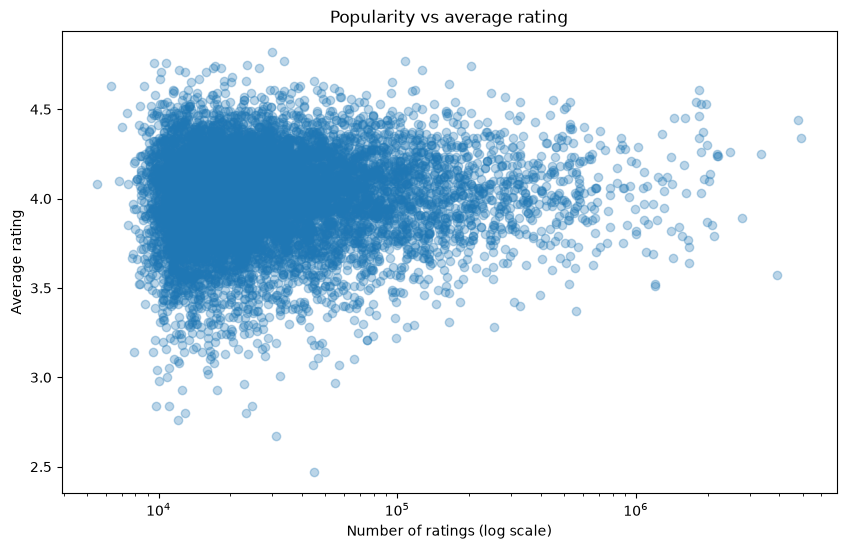

In [12]:
fig = plots.plot_popularity_vs_rating(books)
plt.show()

### Results
Both Pearson and Spearman correlation coefficients indicate a negligible positive relationship between book popularity and average rating.

The scatter plot also shows no clear relationship between the two variables.

These results suggest that more popular books do not necessarily receive higher average ratings.

## 2- Rating distributions
**Research question:** How are ratings distributed across the five rating levels and how do these distributions differ between books?

### Overall rating distribution
The overall rating distribution is calculated using the number of ratings received at each of the five rating levels, from 1 to 5 stars.

The analysis provides an overview of how readers evaluate books across the dataset.

In [13]:
overall_percentages = analysis.overall_rating_distribution(books)

overall_percentages.round(2)

ratings_1     2.25
ratings_2     5.21
ratings_3    19.23
ratings_4    33.45
ratings_5    39.86
dtype: float64

The percentage of positive ratings is calculated by combining the percentages of 4-star and 5-star ratings.

In [14]:
positive_ratings = overall_percentages["ratings_4"] + overall_percentages["ratings_5"]

print(f"Positive ratings: {positive_ratings:.2f}%")

Positive ratings: 73.31%


The overall distribution is visualized using a bar chart showing the percentage of ratings at each star level.

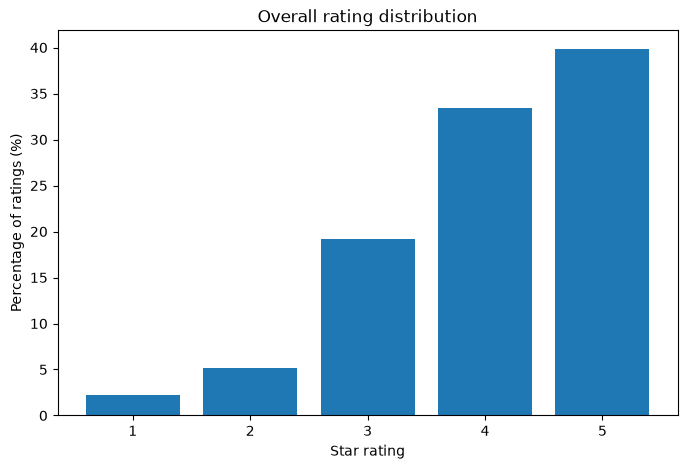

In [15]:
fig = plots.plot_overall_rating_distribution(overall_percentages)
plt.show()

### Individual book rating distribution
Rating distributions can also be explored at the individual book level.

The following table provides examples of available books and their corresponding identifiers.

In [ ]:
books[["book_id", "title", "authors"]].head(5)

,book_id,title,authors
0,1,"The Hunger Games (The Hunger Games, #1)",Suzanne Collins
1,2,Harry Potter and the Sorcerer's Stone (Harry P...,"J.K. Rowling, Mary GrandPré"
2,3,"Twilight (Twilight, #1)",Stephenie Meyer
3,4,To Kill a Mockingbird,Harper Lee
4,5,The Great Gatsby,F. Scott Fitzgerald


A specific book can be selected by changing the value of `selected_id` and running the following cells again.

In [17]:
selected_id = 1

selected_book = books[books["book_id"] == selected_id].iloc[0]

print("Title:", selected_book["title"])
print("Author:", selected_book["authors"])
print(f"Average rating: {selected_book['average_rating']:.2f} / 5")

Title: The Hunger Games (The Hunger Games, #1)
Author: Suzanne Collins
Average rating: 4.34 / 5


The `individual_rating_distribution()` function calculates the percentage of ratings at each star level for the selected book.

In [18]:
rating_distribution = analysis.individual_rating_distribution(selected_book)

rating_distribution

,Stars,Percentage
0,1,1.349860
1,2,2.588558
2,3,11.332469
3,4,29.971582
4,5,54.757530


The rating distribution of the selected book is visualized using a bar chart. The y-axis ranges from 0 to 100 to facilitate comparisons between different books.

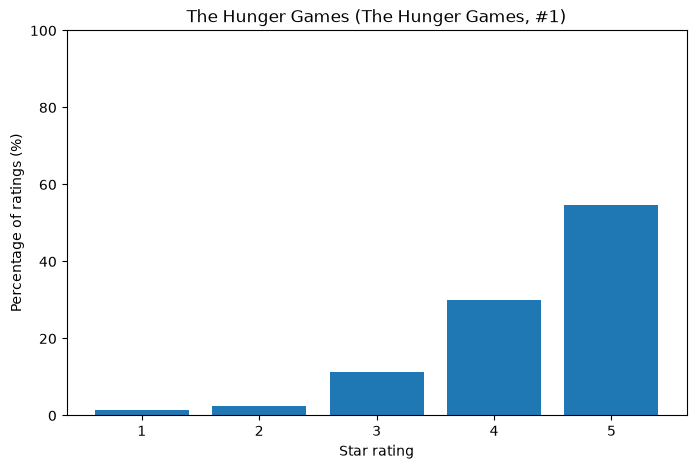

In [19]:
fig = plots.plot_individual_rating_distribution(
    rating_distribution, selected_book["title"]
)

plt.show()

### Results
Overall, 73.31% of ratings are 4 or 5 stars, indicating a predominance of positive evaluations.

However, rating distributions vary across individual books. Changing the selected book allows different rating patterns to be explored and compared.

## 3- Reader behavior
**Research question:** Do more active readers rate books differently?

This section investigates the relationship between user rating activity and the average rating assigned by each user.

### User statistics
The `calculate_user_stats()` function calculates the total number of ratings and the average rating for each user.

In [20]:
user_stats = analysis.calculate_user_stats(ratings)

user_stats.head()

,user_id,number_of_ratings,average_rating
0,1,117,3.589744
1,2,65,4.415385
2,3,91,1.736264
3,4,134,3.768657
4,5,100,4.040000


### Reader activity and average rating
Pearson and Spearman correlation coefficients are calculated to investigate the relationship between the number of ratings assigned by each user and their average rating.

In [21]:
pearson, spearman = analysis.reader_behavior_correlations(user_stats)

print(f"Pearson correlation: {pearson:.3f}")
print(f"Spearman correlation: {spearman:.3f}")

Pearson correlation: -0.083
Spearman correlation: -0.099


The relationship between reader activity and average rating is visualized using a scatter plot, where each point represents an individual user.

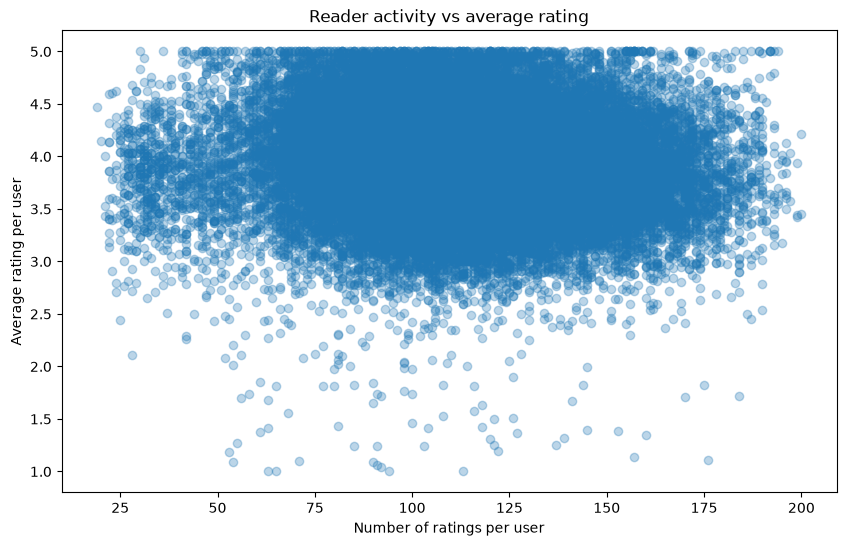

In [22]:
fig = plots.plot_reader_activity(user_stats)

plt.show()

### Reader activity groups
Users are divided into four groups based on their rating activity: Low, Medium-low, Medium-high and High.

The `calculate_activity_groups()` function uses quartiles to create the four groups and calculates the number of users and the mean of their individual average ratings for each group.

In [23]:
activity_summary = analysis.calculate_activity_groups(user_stats)

activity_summary.round(2)

,activity_group,number_of_users,mean_rating
0,Low,13897,3.99
1,Medium-low,13535,3.93
2,Medium-high,13040,3.91
3,High,12952,3.88


The mean rating of each activity group is visualized using a line plot.

The y-axis is restricted to the interval from 3.8 to 4.1 to highlight small differences between the groups (0.11 stars).

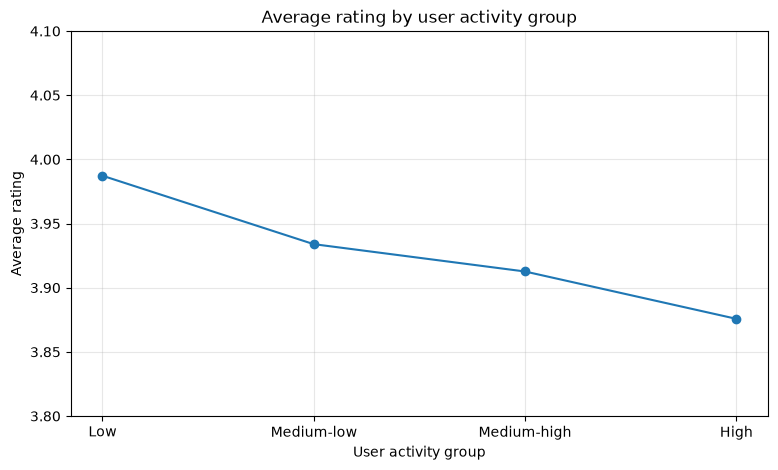

In [24]:
fig = plots.plot_activity_groups(activity_summary)

plt.show()

### Results
Both Pearson and Spearman correlation coefficients indicate a very weak negative relationship between reader activity and average rating.

The activity group analysis shows that more active readers tend to assign slightly lower ratings, the difference between the two groups is only 0.11 points.

These results suggest that reader activity alone does not strongly explain differences in rating behavior.

## 4- Publication year
**Research question:** Is there a relationship between a book's publication year and its average rating?

This section investigates the relationship between publication year and average book rating and explores how average ratings change over time.

### Publication year and average rating
Pearson and Spearman correlation coefficients are calculated using all books with a known publication year.

In [25]:
pearson, spearman = analysis.publication_year_correlations(books)

print(f"Pearson correlation: {pearson:.3f}")
print(f"Spearman correlation: {spearman:.3f}")

Pearson correlation: 0.016
Spearman correlation: -0.027


The relationship between publication year and average rating is visualized using a scatter plot, where each point represents an individual book.

For readability, only books published from the year 1000 onwards are included in the visualization.

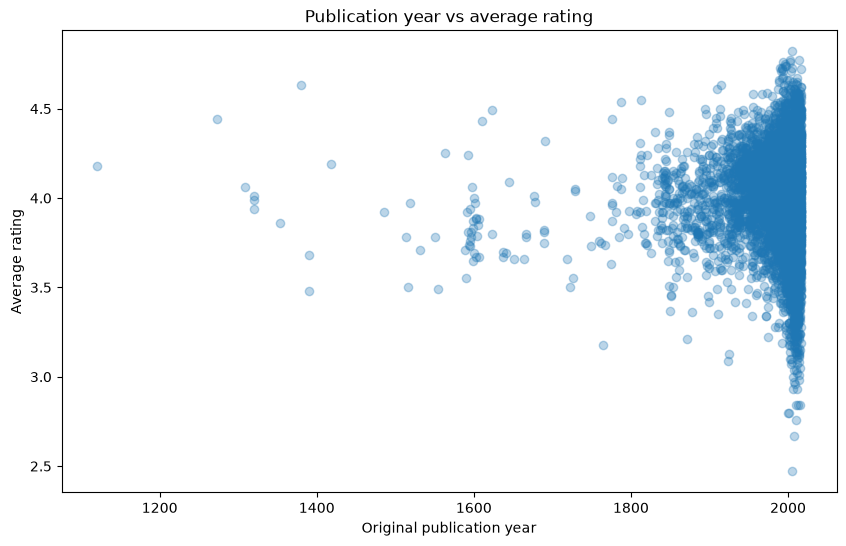

In [26]:
fig = plots.plot_publication_year_vs_rating(books)

plt.show()

### Average rating by decade
Books published from 1800 onwards are grouped by publication decade.

For each decade, the mean of the average book ratings and the number of books are calculated.

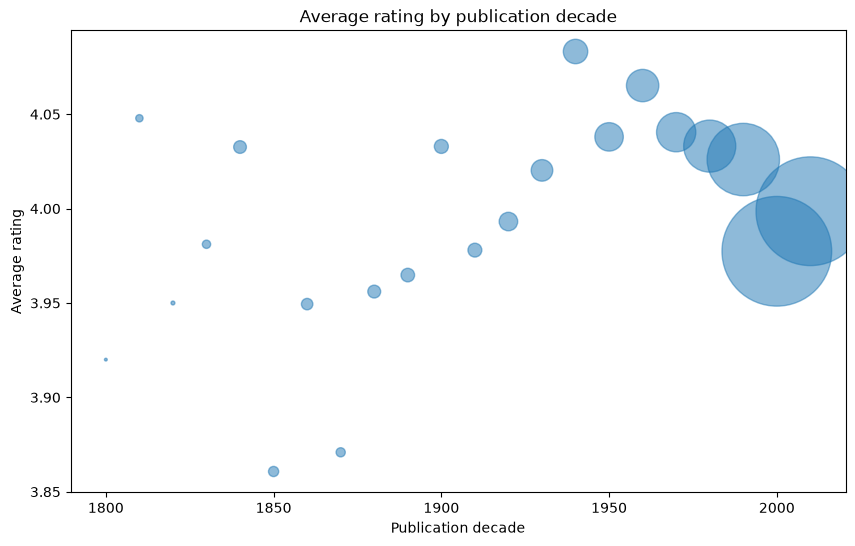

In [27]:
fig = plots.plot_average_rating_by_decade(books)

plt.show()

The bubble chart is used to visualize average ratings by publication decade.

The size of each bubble represents the number of books published in the corresponding decade.

### Average rating by year
To explore more recent publication trends, books published between 1980 and 2017 are grouped by publication year.

A line plot shows how average book ratings change over time.

The year 2017 is represented by only 11 books. Therefore, its average rating should be interpreted with caution.

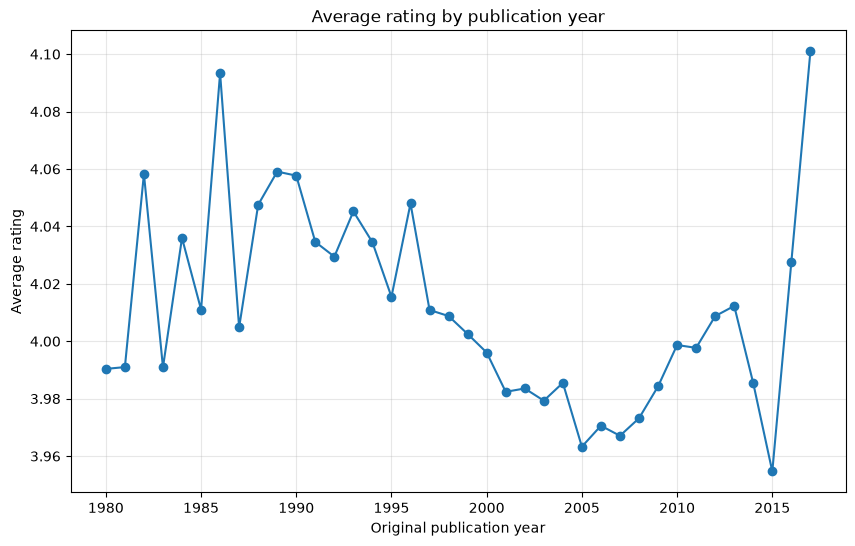

In [28]:
fig = plots.plot_average_rating_by_year(books)

plt.show()

## Conclusions
The analysis of the Goodbooks-10k dataset shows the following results:
- **Popularity & ratings:** book popularity shows a negligible relationship with average rating.
- **Rating distributions:** ratings are generally positive, with 73.31% of ratings corresponding to four or five stars.
- **Reader behavior:** more active readers tend to assign slightly lower ratings, although the relationship is very weak.
- **Publication year:** publication year shows negligible correlations with average book rating.

Overall, popularity, reader activity and publication year do not individually explain much of the variation in average ratings.

### Limitations
The dataset contains a selection of popular books from Goodreads and may not be representative of all published books or readers.

Some publication periods contain relatively few books, making their average ratings less representative.

Finally, correlation measures statistical association and does not imply causation.

## Interactive Streamlit application
The project also includes a Streamlit dashboard that presents the main analysis results and allows users to explore book ratings and publication trends interactively.

Users can select individual books, explore their rating distributions and customize publication periods and grouping options.

[Open the Page Turners dashboard](https://pageturners-apjsanp6cplbz5cwapjyd5.streamlit.app/)